# Application Credit Scorecard - Give Me Some Credit (150K borrowers)

**Goal:** decide, at the point of application, who to approve, at what terms, and who to decline,
using a transparent points-based scorecard that a credit committee and a regulator can read.

**Plan**
1. EDA and cleaning
2. WoE binning and Information Value (IV)
3. Logistic regression scorecard - the *champion*
4. LightGBM - the *challenger*
5. Validation and monitoring (Gini, KS, gains, PSI/CSI)
6. Business strategy: profit-based cut-off and risk bands A-E
7. Save artifacts for the scoring app

Target: `SeriousDlqin2yrs` = 1 if the borrower went 90+ days past due within 2 years ("bad").
All cleaning, binning and model fitting use the **training split only** (70%); the 30% test split is
touched only for evaluation.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from matplotlib.colors import LinearSegmentedColormap

from src import config, data_prep, binning, scorecard, challenger, validation as V, strategy as S

config.set_plot_style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
FIG = config.FIG_DIR
FIG.mkdir(parents=True, exist_ok=True)
config.MODELS_DIR.mkdir(exist_ok=True)
np.random.seed(config.SEED)
results = {}

## 1. EDA and cleaning

In [2]:
df = data_prep.load_raw()
print("Shape:", df.shape)
print(f"Overall bad rate: {df[config.TARGET].mean():.2%}  (about 1 bad in {1/df[config.TARGET].mean():.0f} borrowers)")
data_prep.data_quality_report(df)

Shape: (150000, 11)
Overall bad rate: 6.68%  (about 1 bad in 15 borrowers)


,dtype,missing_pct,min,median,p99,max
SeriousDlqin2yrs,int64,0.0000,0.0000,0.0000,1.0000,1.0000
RevolvingUtil,float64,0.0000,0.0000,0.1542,1.0930,"50,708.0000"
Age,int64,0.0000,0.0000,52.0000,87.0000,109.0000
PastDue30_59,int64,0.0000,0.0000,0.0000,4.0000,98.0000
DebtRatio,float64,0.0000,0.0000,0.3665,"4,979.0400","329,664.0000"
MonthlyIncome,float64,19.8200,0.0000,"5,400.0000","25,000.0000","3,008,750.0000"
OpenCreditLines,int64,0.0000,0.0000,8.0000,24.0000,58.0000
PastDue90Plus,int64,0.0000,0.0000,0.0000,3.0000,98.0000
RealEstateLoans,int64,0.0000,0.0000,1.0000,4.0000,54.0000
PastDue60_89,int64,0.0000,0.0000,0.0000,2.0000,98.0000


**What the raw data tells us**
- `MonthlyIncome` is missing for ~20% of borrowers and `Dependents` for ~2.6%.
- `RevolvingUtil` should sit between 0 and 1 but reaches 50,708, which is clearly bad data.
- The three past-due counts contain the codes **96 / 98**. These are system codes, not real counts.
- One borrower has `Age` = 0.
- `DebtRatio` has huge values, mostly where income is missing: the ratio can't be computed, so the raw
  debt amount seems to have been stored instead.

Let's check whether the missing values and special codes carry risk information before deciding how to treat them.

In [3]:
miss_inc = df.groupby(df["MonthlyIncome"].isna())[config.TARGET].agg(["count", "mean"])
miss_inc.index = ["Income reported", "Income missing"]
special = df["PastDue90Plus"].isin([96, 98])
print(miss_inc.rename(columns={"mean": "bad_rate"}), "\n")
print(f"Rows with 96/98 past-due codes: {special.sum()}, bad rate {df.loc[special, config.TARGET].mean():.1%}")
over = df["RevolvingUtil"] > 1
print(f"RevolvingUtil > 1: {over.mean():.2%} of rows, bad rate {df.loc[over, config.TARGET].mean():.1%}")

                  count  bad_rate
Income reported  120269    0.0695
Income missing    29731    0.0561 

Rows with 96/98 past-due codes: 269, bad rate 54.6%
RevolvingUtil > 1: 2.21% of rows, bad rate 37.2%


**Treatment decisions (fitted on train only)**

| Issue | Treatment | Why |
|---|---|---|
| Missing `MonthlyIncome` / `Dependents` | Kept as NaN. The binning step gives them their own **Missing** bin | Missing income has a *lower* bad rate than average. Median imputation would hide that and pull these borrowers towards the wrong risk group. LightGBM handles NaN natively. |
| 96/98 past-due codes | Replaced with the highest genuine count in train | These ~270 rows default at ~55%, so they belong in the riskiest bin, not at 96 delinquencies |
| `RevolvingUtil` > 1 | Capped at 1 | Over-limit borrowers stay in the top-risk bin, and values in the thousands are data errors |
| `Age` = 0 | Train median | Impossible value (one row) |
| `DebtRatio`, `MonthlyIncome` | Capped at train 99th / 99.9th percentile | Limits the influence of extreme values |

In [4]:
X_train, X_test, y_train, y_test = data_prep.split(df)
cleaner = data_prep.Cleaner().fit(X_train)
Xtr, Xte = cleaner.transform(X_train), cleaner.transform(X_test)
print(f"Train: {len(Xtr):,} rows, bad rate {y_train.mean():.2%} | Test: {len(Xte):,} rows, bad rate {y_test.mean():.2%}")
print("Learned thresholds:", cleaner)
train_df = Xtr.assign(**{config.TARGET: y_train})

Train: 105,000 rows, bad rate 6.68% | Test: 45,000 rows, bad rate 6.68%
Learned thresholds: Cleaner(util_cap=1.0, past_due_caps={'PastDue30_59': 13.0, 'PastDue60_89': 11.0, 'PastDue90Plus': 17.0}, age_median=52.0, debt_ratio_cap=4977.0199999999895, income_cap=78000.0)


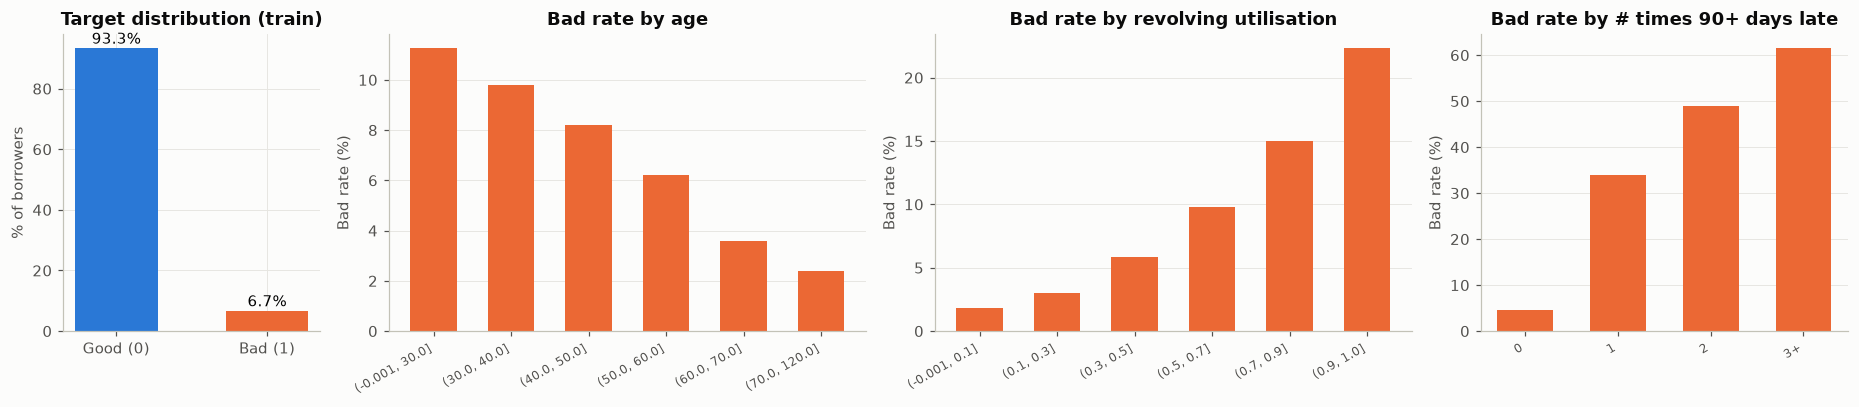

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), gridspec_kw={"width_ratios": [0.7, 1.3, 1.3, 1]})
counts = y_train.value_counts().sort_index()
axes[0].bar(["Good (0)", "Bad (1)"], counts.values / counts.sum() * 100, color=[config.GOOD_COLOR, config.BAD_COLOR], width=0.55)
for i, v in enumerate(counts.values / counts.sum() * 100):
    axes[0].annotate(f"{v:.1f}%", (i, v), xytext=(0, 3), textcoords="offset points", ha="center")
axes[0].set_title("Target distribution (train)"); axes[0].set_ylabel("% of borrowers")

panels = [
    ("Age", [0, 30, 40, 50, 60, 70, 120], "Bad rate by age"),
    ("RevolvingUtil", [0, .1, .3, .5, .7, .9, 1.0], "Bad rate by revolving utilisation"),
    ("PastDue90Plus", [-.5, .5, 1.5, 2.5, 20], "Bad rate by # times 90+ days late"),
]
for ax, (col, bins, title) in zip(axes[1:], panels):
    t = data_prep.bad_rate_by(train_df, col, bins)
    if col == "PastDue90Plus":
        t.index = ["0", "1", "2", "3+"]
    ax.bar(range(len(t)), t["bad_rate"] * 100, color=config.BAD_COLOR, width=0.6)
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, rotation=30, ha="right", fontsize=8)
    ax.set_title(title); ax.set_ylabel("Bad rate (%)"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(FIG / "01_eda_bad_rates.png"); plt.show()

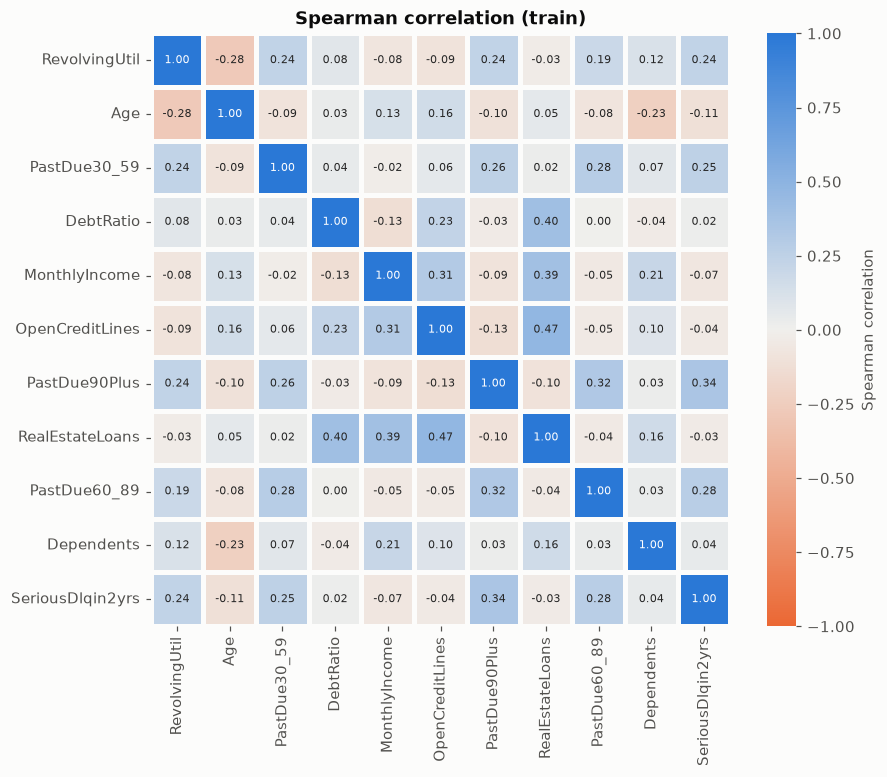

In [6]:
corr = train_df.corr(method="spearman")
div = LinearSegmentedColormap.from_list("div", [config.BAD_COLOR, config.NEUTRAL, config.GOOD_COLOR])
plt.figure(figsize=(8.5, 7))
sns.heatmap(corr, cmap=div, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=2, linecolor=config.SURFACE, cbar_kws={"label": "Spearman correlation"})
plt.title("Spearman correlation (train)")
plt.savefig(FIG / "02_correlation_heatmap.png"); plt.show()

The three past-due counts are correlated with each other and with default. Utilisation is the
strongest single driver among the continuous variables. Spearman correlation is used because the
variables are heavily skewed.

## 2. WoE binning and Information Value

Each variable is grouped into bins, and each bin is replaced by its **Weight of Evidence**:
WoE = ln(%goods in bin / %bads in bin). Positive WoE means the bin is safer than average.
**IV** = Σ (%good − %bad) × WoE measures how well the variable separates goods from bads.

*Implementation note:* optbinning can't be installed on Python 3.15 (it depends on Google OR-Tools,
which has no 3.15 build). So `src/binning.py` follows the same two-stage approach:
1. **Fine classing:** a shallow decision tree proposes cut points, with at least 2% of borrowers per bin.
2. **Coarse classing:** adjacent bins are merged until the bad rate is **monotonic**, so a scorecard
   never rewards e.g. more delinquencies.

Missing values get their own bin.

In [7]:
bp = binning.BinningProcess(config.FEATURES).fit(Xtr, y_train)
iv_table = bp.iv_table()
iv_table.to_csv(config.REPORTS_DIR / "iv_table.csv", index=False)
iv_table

,Feature,IV,Bins,Strength
0,RevolvingUtil,1.1102,6,Very strong (check for leakage)
1,PastDue90Plus,0.8866,3,Very strong (check for leakage)
2,PastDue30_59,0.7374,4,Very strong (check for leakage)
3,PastDue60_89,0.5753,2,Very strong (check for leakage)
4,Age,0.2382,6,Medium
5,OpenCreditLines,0.0925,5,Weak
6,MonthlyIncome,0.0764,6,Weak
7,RealEstateLoans,0.0389,2,Weak
8,Dependents,0.0357,6,Weak
9,DebtRatio,0.0200,3,Weak


**Reading the IV table**
- Utilisation and the three past-due counts score above 0.5. Normally that would be a reason to suspect
  leakage. Here it doesn't apply: they are measured *before* the outcome window, and past delinquency
  being the best predictor of future delinquency is the standard credit result. They stay in.
- Nothing scores below the 0.02 "useless" threshold. `DebtRatio` only just clears it (IV 0.020), so it
  goes forward as a weak variable for the model to keep or drop.

Kept: ['RevolvingUtil', 'PastDue90Plus', 'PastDue30_59', 'PastDue60_89', 'Age', 'OpenCreditLines', 'MonthlyIncome', 'RealEstateLoans', 'Dependents', 'DebtRatio'] 
Dropped (IV < 0.02): []


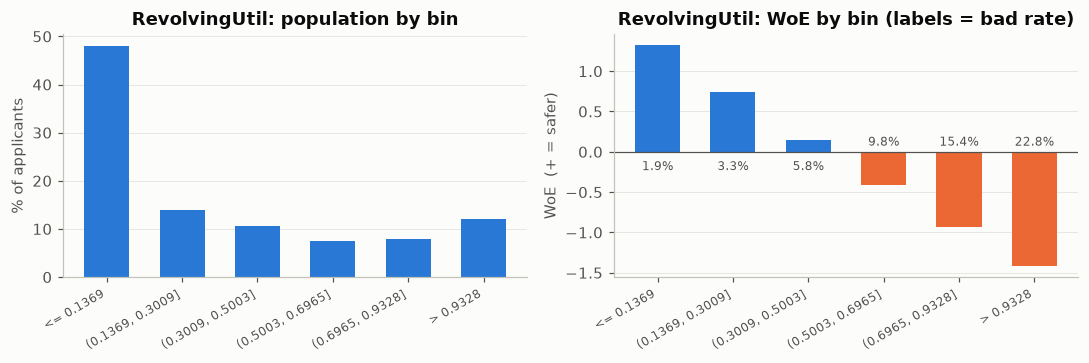

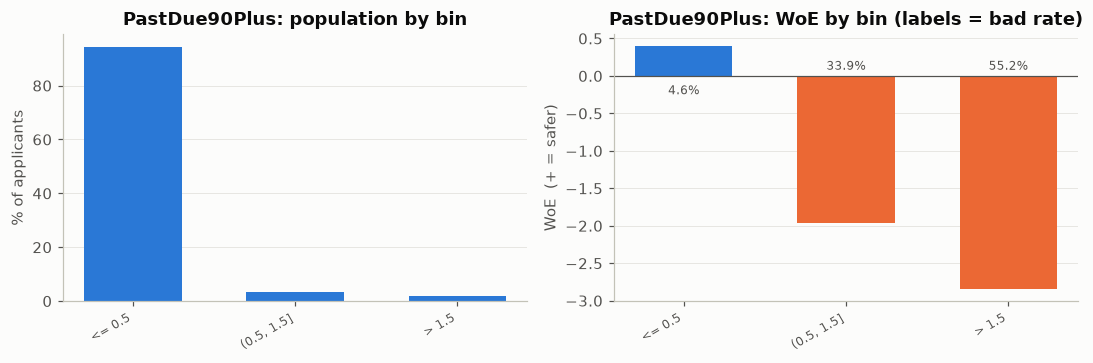

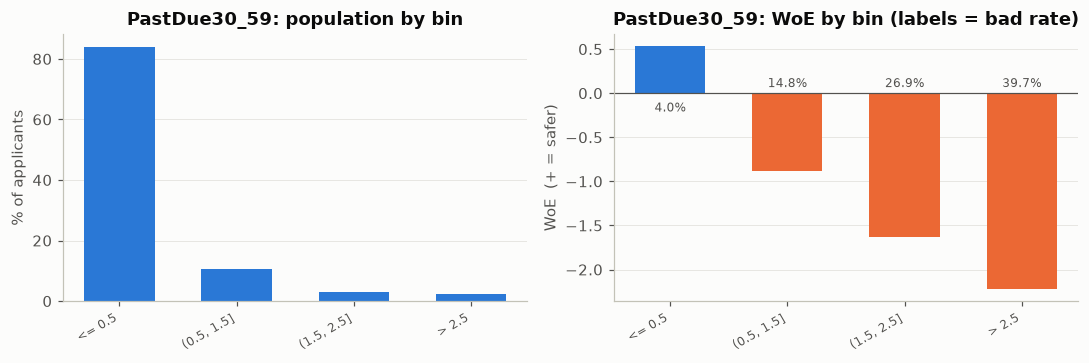

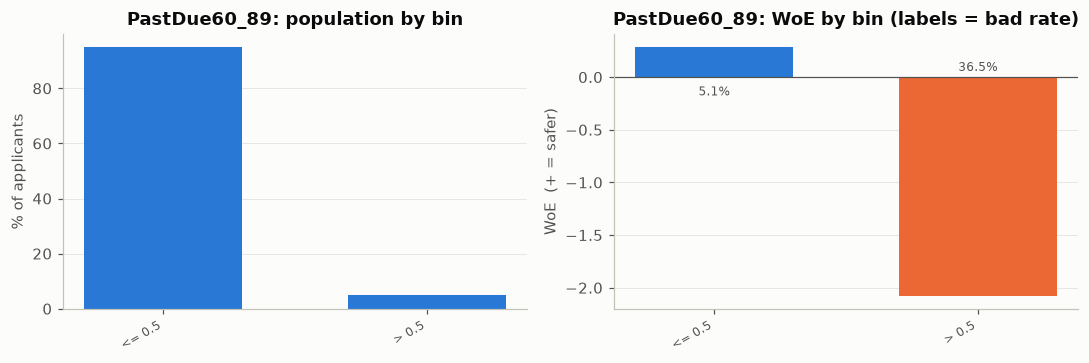

In [8]:
keep = iv_table.loc[iv_table["IV"] >= 0.02, "Feature"].tolist()
dropped_iv = iv_table.loc[iv_table["IV"] < 0.02, "Feature"].tolist()
print("Kept:", keep, "\nDropped (IV < 0.02):", dropped_iv)

for f in iv_table["Feature"].head(4):
    bp.plot(f); plt.tight_layout(); plt.savefig(FIG / f"03_woe_{f}.png"); plt.show()

In [9]:
pd.concat([bp.table(f) for f in keep]).reset_index(drop=True)

,Feature,Bin,Count,Count %,Goods,Bads,Bad rate,WoE,IV
0,RevolvingUtil,<= 0.1369,50459,0.4806,49514,945,0.0187,1.3220,0.4900
1,RevolvingUtil,"(0.1369, 0.3009]",14569,0.1388,14091,478,0.0328,0.7464,0.0565
2,RevolvingUtil,"(0.3009, 0.5003]",11064,0.1054,10417,647,0.0585,0.1418,0.0020
3,RevolvingUtil,"(0.5003, 0.6965]",7846,0.0747,7080,766,0.0976,-0.4130,0.0153
4,RevolvingUtil,"(0.6965, 0.9328]",8361,0.0796,7075,1286,0.1538,-0.9316,0.1035
5,RevolvingUtil,> 0.9328,12701,0.1210,9805,2896,0.2280,-1.4169,0.4430
6,PastDue90Plus,<= 0.5,99103,0.9438,94545,4558,0.0460,0.3958,0.1248
7,PastDue90Plus,"(0.5, 1.5]",3723,0.0355,2462,1261,0.3387,-1.9674,0.3042
8,PastDue90Plus,> 1.5,2174,0.0207,975,1199,0.5515,-2.8430,0.4576
9,PastDue30_59,<= 0.5,88178,0.8398,84618,3560,0.0404,0.5319,0.1895


## 3. Logistic regression scorecard (champion)

The model is a logistic regression on the WoE values. Two checks guard its quality:
- **Multicollinearity:** VIF > 5 means a variable is largely explained by the others, so the lowest-IV
  one in the group is dropped.
- **Business logic:** with WoE defined as good/bad and the model predicting *bad*, every coefficient must be
  **negative**. A positive coefficient would mean a safer bin gets fewer points. Such variables are dropped, as
  are those with p > 0.05.

In [10]:
Wtr, Wte = bp.transform(Xtr, keep), bp.transform(Xte, keep)
cols, dropped_vif, vif = scorecard.select_by_vif(Wtr, iv_table.set_index("Feature")["IV"], threshold=5)
print("Dropped for VIF > 5:", dropped_vif or "none")
vif.to_frame()

Dropped for VIF > 5: none


,VIF
RealEstateLoans,1.3356
RevolvingUtil,1.3091
OpenCreditLines,1.2890
PastDue90Plus,1.2473
PastDue30_59,1.2114
PastDue60_89,1.2014
Dependents,1.1739
Age,1.1581
DebtRatio,1.1243
MonthlyIncome,1.0896


In [11]:
lr, final_features, drop_log = scorecard.fit_with_checks(Wtr, y_train, cols)
for f, why in drop_log:
    print(f"Dropped {f}: {why}")
print("Final features:", final_features)
lr.summary2()

Dropped OpenCreditLines: positive coefficient +0.082 (p=0.095)
Final features: ['RevolvingUtil', 'PastDue90Plus', 'PastDue30_59', 'PastDue60_89', 'Age', 'MonthlyIncome', 'RealEstateLoans', 'Dependents', 'DebtRatio']


<class 'statsmodels.iolib.summary2.Summary'>
"""
                         Results: Logit
=================================================================
Model:              Logit            Method:           MLE       
Dependent Variable: SeriousDlqin2yrs Pseudo R-squared: 0.251     
Date:               2026-10-28 00:26 AIC:              38602.6674
No. Observations:   105000           BIC:              38698.2846
Df Model:           9                Log-Likelihood:   -19291.   
Df Residuals:       104990           LL-Null:          -25765.   
Converged:          1.0000           LLR p-value:      0.0000    
No. Iterations:     8.0000           Scale:            1.0000    
-----------------------------------------------------------------
                 Coef.  Std.Err.     z     P>|z|   [0.025  0.975]
-----------------------------------------------------------------
const           -2.6062   0.0151 -172.7377 0.0000 -2.6357 -2.5766
RevolvingUtil   -0.6239   0.0146  -42.6377 0.0000 -0.6526 -0.5952
PastDue90Plus   -0.5248   0.0135  -38.9846 0.0000 -0.5511 -0.4984
PastDue30_59    -0.5083   0.0155  -32.7982 0.0000 -0.5387 -0.4780
PastDue60_89    -0.3913   0.0169  -23.1636 0.0000 -0.4244 -0.3582
Age             -0.4196   0.0330  -12.7299 0.0000 -0.4842 -0.3550
MonthlyIncome   -0.3651   0.0533   -6.8540 0.0000 -0.4695 -0.2607
RealEstateLoans -0.1840   0.0825   -2.2311 0.0257 -0.3456 -0.0224
Dependents      -0.4400   0.0767   -5.7362 0.0000 -0.5903 -0.2897
DebtRatio       -1.3027   0.1082  -12.0413 0.0000 -1.5148 -1.0907
=================================================================

"""

`OpenCreditLines` was removed. With the other variables in the model its coefficient turns positive and
loses significance (p ≈ 0.09). Its signal is mostly captured by utilisation and the delinquency counts.
Every remaining coefficient is negative and significant.

**Points scaling:** 600 points at good:bad odds of 50:1, and every **20 points (PDO) doubles the odds**.
- Factor = 20 / ln 2 = 28.85
- Offset = 600 − 28.85 × ln 50 = 487.12
- Points for a bin = −(β × WoE + β₀/n) × Factor + Offset/n

An applicant's score is the sum of the points from each of their bins.

In [12]:
card = scorecard.Scorecard(bp, lr, final_features)
print(f"Factor = {card.factor:.4f}, Offset = {card.offset:.4f}")
card.table_.to_csv(config.MODELS_DIR / "scorecard_table.csv", index=False)
card.table_[["Feature", "Bin", "Count %", "Bad rate", "WoE", "Points"]]

Factor = 28.8539, Offset = 487.1229


,Feature,Bin,Count %,Bad rate,WoE,Points
0,RevolvingUtil,<= 0.1369,0.4806,0.0187,1.3220,86
1,RevolvingUtil,"(0.1369, 0.3009]",0.1388,0.0328,0.7464,76
2,RevolvingUtil,"(0.3009, 0.5003]",0.1054,0.0585,0.1418,65
3,RevolvingUtil,"(0.5003, 0.6965]",0.0747,0.0976,-0.4130,55
4,RevolvingUtil,"(0.6965, 0.9328]",0.0796,0.1538,-0.9316,46
5,RevolvingUtil,> 0.9328,0.1210,0.2280,-1.4169,37
6,PastDue90Plus,<= 0.5,0.9438,0.0460,0.3958,68
7,PastDue90Plus,"(0.5, 1.5]",0.0355,0.3387,-1.9674,33
8,PastDue90Plus,> 1.5,0.0207,0.5515,-2.8430,19
9,PastDue30_59,<= 0.5,0.8398,0.0404,0.5319,70


Check: summing the points table vs the model's own score - mean |diff| 1.10, max 2.80 points (rounding only)
Score range on test: 419 to 626, median 591


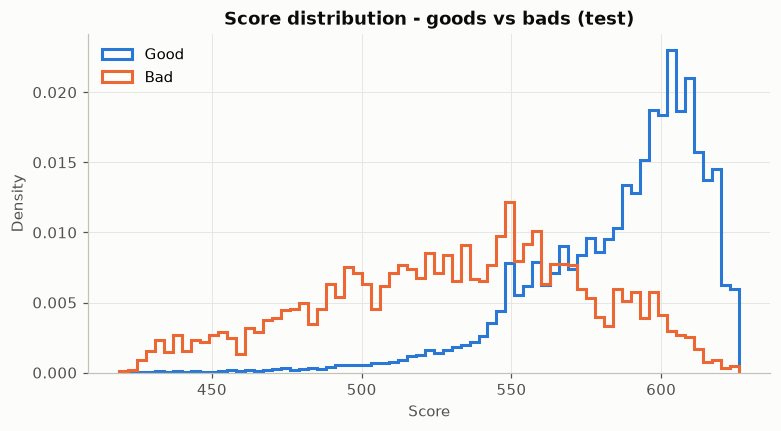

In [13]:
s_tr, s_te = card.score(Xtr), card.score(Xte)
diff = (s_te - card.model_score(Wte)).abs()
print(f"Check: summing the points table vs the model's own score - mean |diff| {diff.mean():.2f}, max {diff.max():.2f} points (rounding only)")
print(f"Score range on test: {s_te.min()} to {s_te.max()}, median {s_te.median():.0f}")

fig, ax = plt.subplots(figsize=(8, 4))
bins_ = np.arange(s_te.min(), s_te.max() + 3, 3)
for lab, mask, c in [("Good", y_test == 0, config.GOOD_COLOR), ("Bad", y_test == 1, config.BAD_COLOR)]:
    ax.hist(s_te[mask], bins=bins_, density=True, histtype="step", linewidth=2, color=c, label=lab)
ax.set_xlabel("Score"); ax.set_ylabel("Density"); ax.set_title("Score distribution - goods vs bads (test)")
ax.legend(); plt.savefig(FIG / "04_score_distribution.png"); plt.show()

## 4. ML challenger - LightGBM

A gradient-boosted tree model trained on the cleaned raw features (no WoE). It can pick up
non-linear effects and interactions that the scorecard can't.

Tuning is a small randomized search: 15 settings × 3-fold stratified CV, scored on AUC. The 6.7% bad
rate is handled by including `scale_pos_weight` (up-weighting bads) in the search.

In [14]:
search = challenger.tune_lgbm(Xtr, y_train, n_iter=15, cv=3)
lgbm = search.best_estimator_
print("Best CV AUC:", round(search.best_score_, 4))
print("Best params:", search.best_params_)
joblib.dump(lgbm, config.MODELS_DIR / "lgbm_challenger.joblib")
challenger.cv_results_table(search)

Best CV AUC: 0.8657
Best params: {'subsample': 0.85, 'scale_pos_weight': 3.0, 'reg_lambda': 1.0, 'num_leaves': 31, 'n_estimators': 200, 'min_child_samples': 400, 'learning_rate': 0.02, 'colsample_bytree': 0.6}


,mean_test_score,std_test_score,params
0,0.8657,0.0040,"{'subsample': 0.85, 'scale_pos_weight': 3.0, '..."
1,0.8651,0.0039,"{'subsample': 1.0, 'scale_pos_weight': 3.0, 'r..."
2,0.8643,0.0038,"{'subsample': 0.85, 'scale_pos_weight': 7.0, '..."
3,0.8640,0.0040,"{'subsample': 0.85, 'scale_pos_weight': 1.0, '..."
4,0.8626,0.0043,"{'subsample': 0.7, 'scale_pos_weight': 3.0, 'r..."


In [15]:
p_lgb_tr, p_lgb_te = lgbm.predict_proba(Xtr)[:, 1], lgbm.predict_proba(Xte)[:, 1]
rows = []
for name, tr, te in [("Logistic scorecard (champion)", -s_tr, -s_te), ("LightGBM (challenger)", p_lgb_tr, p_lgb_te)]:
    mtr, mte = V.metrics(y_train, tr), V.metrics(y_test, te)
    rows.append({"Model": name, **{f"Train {k}": v for k, v in mtr.items()}, **{f"Test {k}": v for k, v in mte.items()},
                 "Gini gap (train-test)": mtr["Gini"] - mte["Gini"]})
comparison = pd.DataFrame(rows).set_index("Model")
comparison.to_csv(config.REPORTS_DIR / "model_comparison.csv")
comparison.round(4)

,Train AUC,Train Gini,Train KS,Test AUC,Test Gini,Test KS,Gini gap (train-test)
Model,,,,,,,
Logistic scorecard (champion),0.8546,0.7093,0.5506,0.8552,0.7104,0.5500,-0.0011
LightGBM (challenger),0.8795,0.7589,0.6011,0.8668,0.7337,0.5752,0.0253


LightGBM adds a few Gini points on test. It also has a larger train-test gap, which signals it is
fitting some noise, while the scorecard performs the same on train and test. Section 6 explains why
lenders usually keep the scorecard anyway.

D:\codes\DATA_ANALYTICS\Py\credit-scorecard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


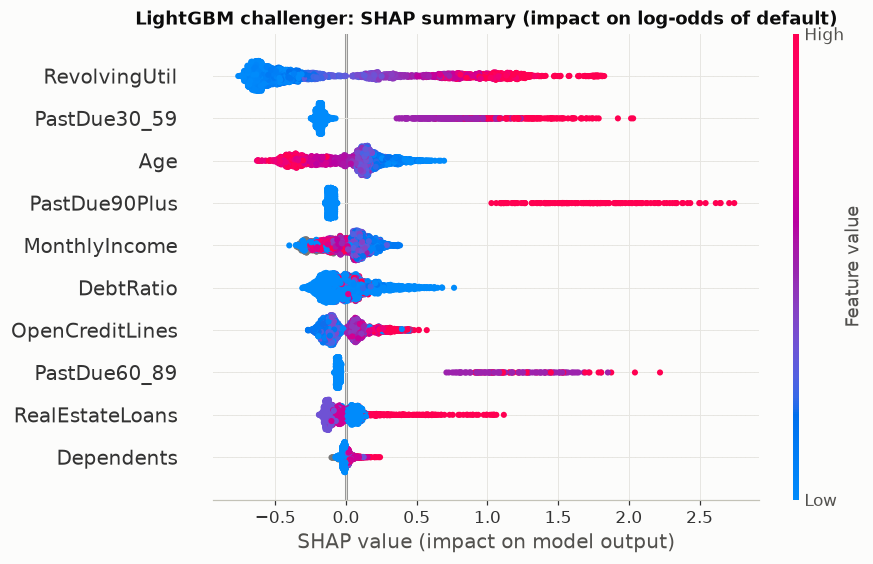

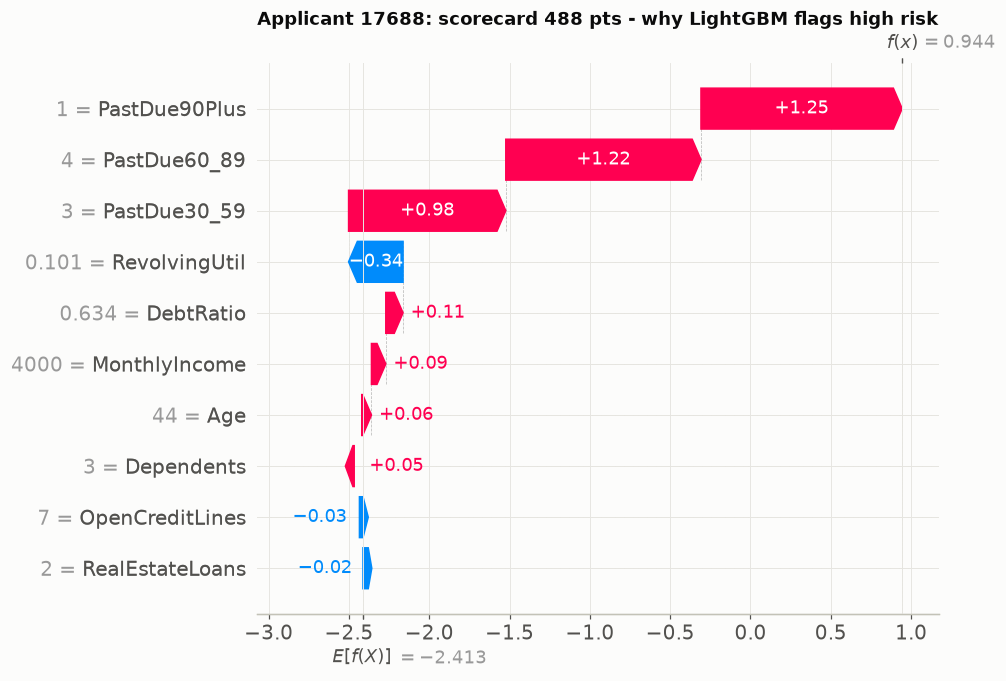

,RevolvingUtil,Age,PastDue30_59,DebtRatio,MonthlyIncome,OpenCreditLines,PastDue90Plus,RealEstateLoans,PastDue60_89,Dependents
17688,0.1007,44,3,0.6338,"4,000.0000",7,1,2,4,3.0000


In [16]:
declined = np.where(s_te.to_numpy() < np.quantile(s_te, 0.05))[0]
focus = int(declined[len(declined) // 2])  # a typical applicant from the riskiest 5%
sample_idx = np.unique(np.r_[np.random.RandomState(config.SEED).choice(len(Xte), 3000, replace=False), focus])
X_shap = Xte.iloc[sample_idx]
exp = challenger.shap_explanation(lgbm, X_shap)
challenger.plot_shap_summary(exp, FIG / "05_shap_summary.png"); plt.show()
pos = int(np.where(sample_idx == focus)[0][0])
challenger.plot_shap_waterfall(exp, pos, FIG / "06_shap_waterfall.png",
                               title=f"Applicant {X_shap.index[pos]}: scorecard {s_te.iloc[focus]} pts - why LightGBM flags high risk"); plt.show()
Xte.iloc[[focus]]

## 5. Validation and monitoring

- **AUC / Gini** (Gini = 2·AUC − 1): how well the model ranks bads below goods across all thresholds.
- **KS:** the maximum gap between the cumulative bad and good distributions, i.e. the best single-cut separation.
- **Gains table:** the share of bads caught in the lowest-score deciles, and whether the bad rate falls steadily as the score rises.
- **PSI / CSI:** whether the population being scored has shifted from the one the model was built on.

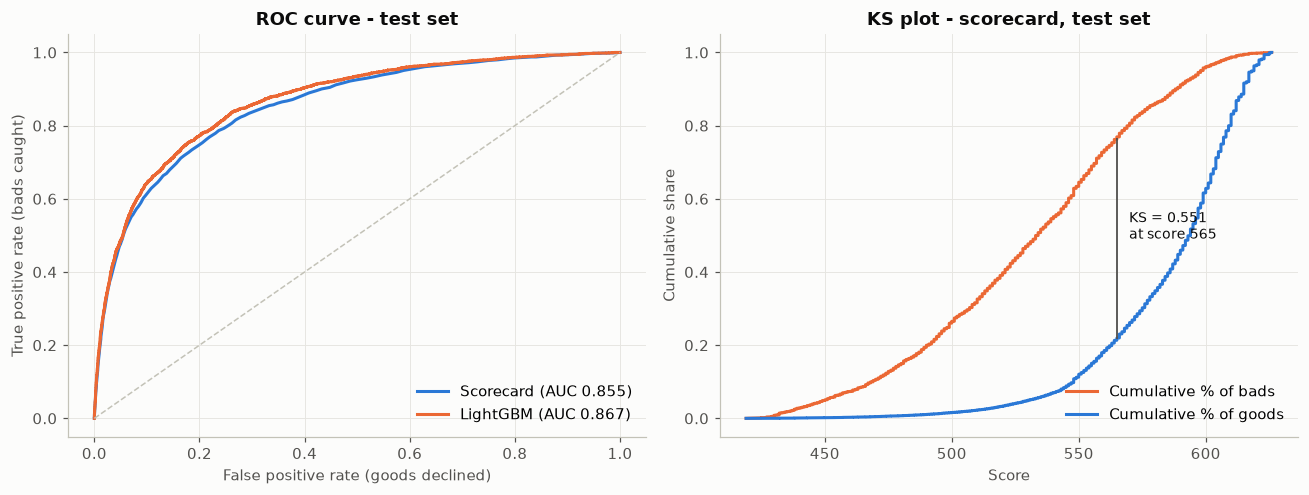

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
V.plot_roc({"Scorecard": (y_test, -s_te), "LightGBM": (y_test, p_lgb_te)}, ax=ax[0])
V.plot_ks(y_test, s_te, ax=ax[1])
plt.tight_layout(); plt.savefig(FIG / "07_roc_ks.png"); plt.show()

In [18]:
gains = V.gains_table(y_test, s_te)
gains.to_csv(config.REPORTS_DIR / "gains_table.csv")
breaks = V.rank_ordering_breaks(gains)
print("Rank-ordering breaks:", breaks or "none - bad rate falls in every decile as score rises")
gains

Rank-ordering breaks: none - bad rate falls in every decile as score rises


,min_score,max_score,count,bads,goods,bad_rate,cum_bads_pct,cum_goods_pct,ks,lift
decile (1 = riskiest),,,,,,,,,,
1,419,539,4500,1635,2865,0.3633,0.5436,0.0682,0.4753,5.4355
2,539,557,4500,496,4004,0.1102,0.7084,0.1636,0.5449,1.6489
3,557,571,4500,306,4194,0.0680,0.8102,0.2635,0.5467,1.0173
4,571,583,4500,172,4328,0.0382,0.8674,0.3665,0.5008,0.5718
5,583,591,4500,146,4354,0.0324,0.9159,0.4702,0.4457,0.4854
6,591,598,4500,89,4411,0.0198,0.9455,0.5753,0.3702,0.2959
7,598,603,4500,70,4430,0.0156,0.9688,0.6807,0.2880,0.2327
8,603,609,4500,44,4456,0.0098,0.9834,0.7869,0.1965,0.1463
9,609,615,4500,31,4469,0.0069,0.9937,0.8933,0.1004,0.1031


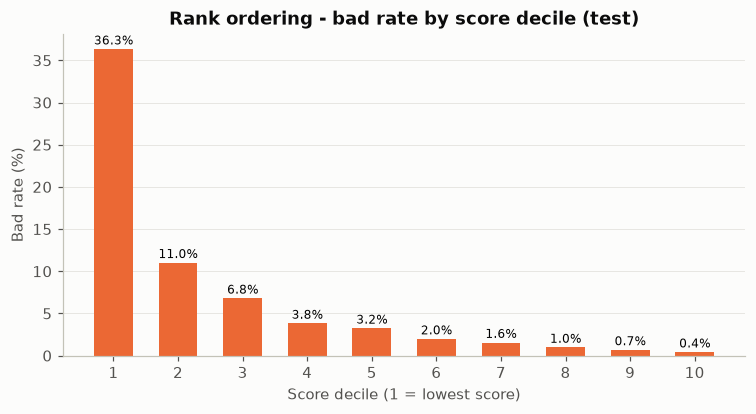

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(gains.index, gains["bad_rate"] * 100, color=config.BAD_COLOR, width=0.6)
for x, v in zip(gains.index, gains["bad_rate"] * 100):
    ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks(gains.index); ax.set_xlabel("Score decile (1 = lowest score)"); ax.set_ylabel("Bad rate (%)")
ax.set_title("Rank ordering - bad rate by score decile (test)"); ax.grid(axis="x", visible=False)
plt.savefig(FIG / "08_rank_ordering.png"); plt.show()

The lowest decile alone holds about half of all bads, and the bad rate falls in every decile.
That is the rank-ordering property a scorecard must have.

In [20]:
psi = V.calculate_psi(s_tr, s_te)
print(f"Score PSI (train -> test): {psi:.5f} -> {V.psi_reading(psi)}")
csi = V.csi_table(bp.bin_indices(Xtr, final_features), bp.bin_indices(Xte, final_features))
csi

Score PSI (train -> test): 0.00027 -> Stable


,Feature,CSI,Reading
0,MonthlyIncome,0.0002,Stable
1,RevolvingUtil,0.0002,Stable
2,DebtRatio,0.0002,Stable
3,Age,0.0001,Stable
4,PastDue90Plus,0.0001,Stable
5,RealEstateLoans,0.0001,Stable
6,Dependents,0.0001,Stable
7,PastDue30_59,0.0000,Stable
8,PastDue60_89,0.0000,Stable


**Honest reading:** PSI is close to zero because train and test come from the *same* random split of
the same period. The useful part here is the mechanism, not the number. In production the same
`calculate_psi()` would compare the development sample with each month's applicants:
- PSI < 0.10: stable
- 0.10 to 0.25: monitor
- above 0.25: investigate

CSI then points to which variable has drifted. A real test of stability needs an out-of-time sample.

## 6. Business strategy - cut-off and risk bands

**Illustrative economics** per loan:
- Average loan ₹2,00,000.
- A good loan earns NIM 12% = **₹24,000**.
- A bad loan loses LGD 60% = **₹1,20,000**.

So one bad costs as much as five goods earn, and an applicant is worth approving only while their bad
rate is below 12 / (12 + 60) = **16.7%**.

The cut-off and band edges are **chosen on the training set** and then **reported on the test set**,
so the strategy isn't tuned on the data used to evaluate it.

In [21]:
cut_train = S.cutoff_table(y_train, s_tr)
best_tr, cons_tr = S.pick_cutoffs(cut_train, tolerance=0.02)
CUTOFF, CONS_CUTOFF = int(best_tr["cutoff"]), int(cons_tr["cutoff"])
print(f"Break-even bad rate: {S.breakeven_bad_rate():.1%}")
print(f"Profit-maximising cut-off (train): {CUTOFF};  conservative alternative (within 2% of max profit): {CONS_CUTOFF}")

cut_test = S.cutoff_table(y_test, s_te)
cut_test.to_csv(config.REPORTS_DIR / "cutoff_table_test.csv", index=False)
row = lambda c: cut_test.set_index("cutoff").loc[c]
approve_all = cut_test.iloc[0]
summary = pd.DataFrame({
    "Approve everyone": approve_all.drop("cutoff"),
    f"Profit-max cut-off {CUTOFF}": row(CUTOFF),
    f"Conservative cut-off {CONS_CUTOFF}": row(CONS_CUTOFF),
}).T
summary["profit (INR cr)"] = summary["profit"] / 1e7
summary[["approval_rate", "bad_rate_approved", "bads_declined_pct", "profit (INR cr)"]]

Break-even bad rate: 16.7%
Profit-maximising cut-off (train): 536;  conservative alternative (within 2% of max profit): 550


,approval_rate,bad_rate_approved,bads_declined_pct,profit (INR cr)
Approve everyone,1.0000,0.0668,0.0000,64.6848
Profit-max cut-off 536,0.9104,0.0355,0.5170,77.3976
Conservative cut-off 550,0.8529,0.0287,0.6340,76.2600


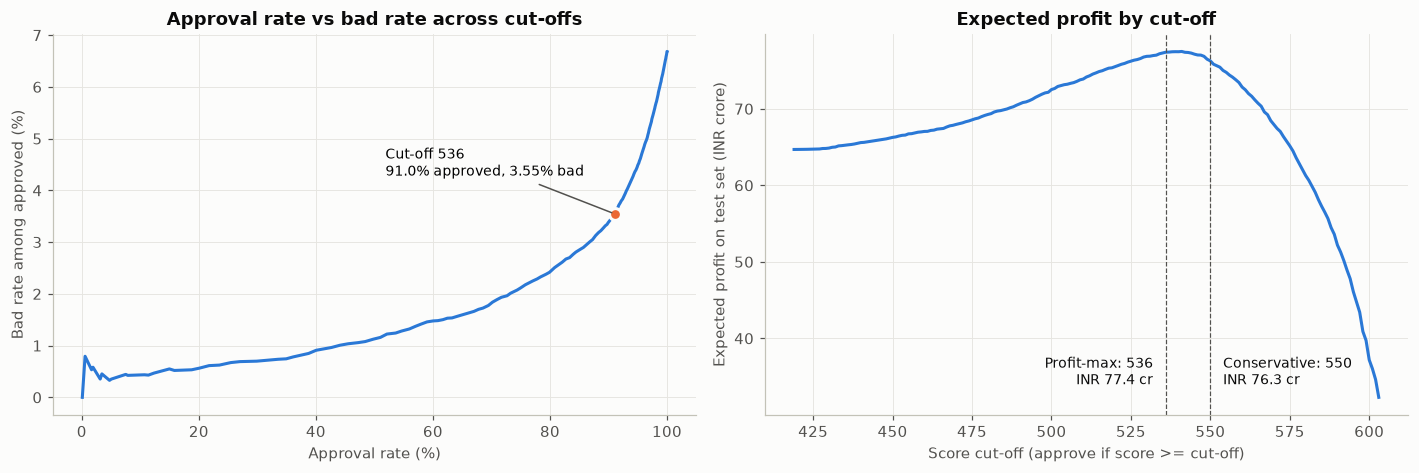

At cut-off 536: approve 91.0%, bad rate 3.55% (vs 6.68% if all approved); profit +INR 12.7 cr on 45,000 test applicants


In [22]:
best_te, cons_te = row(CUTOFF).copy(), row(CONS_CUTOFF).copy()
best_te["cutoff"], cons_te["cutoff"] = CUTOFF, CONS_CUTOFF
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
S.plot_tradeoff(cut_test, best_te, ax=ax[0])
S.plot_profit(cut_test, best_te, cons_te, ax=ax[1])
plt.tight_layout(); plt.savefig(FIG / "09_cutoff_strategy.png"); plt.show()
uplift = best_te["profit"] - approve_all["profit"]
print(f"At cut-off {CUTOFF}: approve {best_te['approval_rate']:.1%}, bad rate {best_te['bad_rate_approved']:.2%} "
      f"(vs {approve_all['bad_rate_approved']:.2%} if all approved); profit +INR {uplift/1e7:,.1f} cr on {len(y_test):,} test applicants")

**Recommendation:** use the **profit-maximising cut-off**. Declining roughly the lowest-scoring 10% of
applicants removes over half of all bads and lifts expected profit by about 20% compared with
approving everyone.

The conservative cut-off gives up less than 2% of profit for a noticeably lower bad rate. It is the better
choice when capital is tight, when LGD is uncertain (an unsecured product with weak recovery), or for
a new-to-credit segment where the model is less proven.

In [23]:
edges = S.band_edges(s_tr, CUTOFF)
bands = S.band_table(y_test, s_te, edges)
bands.to_csv(config.REPORTS_DIR / "risk_bands.csv")
print("Band lower bounds (A, B, C, D):", edges[::-1], "| E is below", CUTOFF)
bands

Band lower bounds (A, B, C, D): [607, 595, 573, 536] | E is below 536


,min_score,max_score,applicants,bads,pct_applicants,bad_rate,action
band,,,,,,,
A,607,626,10585,66,0.2352,0.0062,Auto-approve
B,595,606,9892,146,0.2198,0.0148,Approve with lower limit
C,573,594,10368,320,0.2304,0.0309,Manual review
D,536,572,10122,921,0.2249,0.0910,Approve with higher pricing or collateral
E,419,535,4033,1555,0.0896,0.3856,Decline


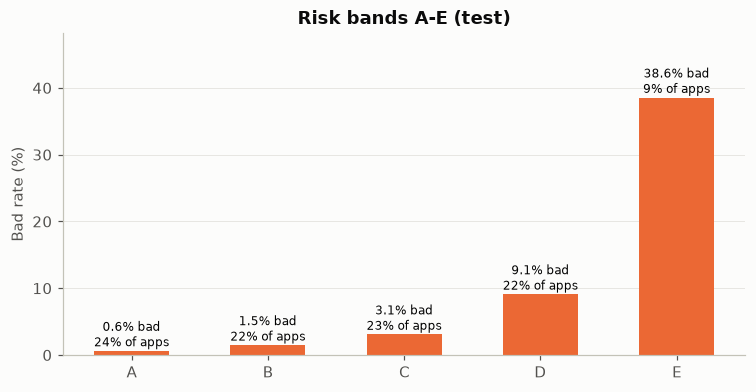

In [24]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(bands.index, bands["bad_rate"] * 100, color=config.BAD_COLOR, width=0.55)
for x, (br, pc) in enumerate(zip(bands["bad_rate"] * 100, bands["pct_applicants"] * 100)):
    ax.annotate(f"{br:.1f}% bad\n{pc:.0f}% of apps", (x, br), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
ax.set_ylabel("Bad rate (%)"); ax.set_title("Risk bands A-E (test)"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, bands["bad_rate"].max() * 100 * 1.25)
plt.savefig(FIG / "10_risk_bands.png"); plt.show()

**Why the logistic scorecard stays the champion and ML is the challenger**

LightGBM ranks borrowers a little better here, but lenders still run the scorecard in production:
- **Explainable decisions:** every point can be traced to a bin, so each decline has clear reason codes,
  and credit policy can review and sign off the points table.
- **Regulation:** RBI's model-risk and fair-lending expectations ask lenders to justify and document
  automated credit decisions, and monotonic, sign-checked WoE variables make that straightforward.
- **Stability:** the scorecard shows almost no train-test gap and is less sensitive to drift. It is also
  simple to monitor with PSI/CSI and to recalibrate.

The challenger runs alongside. It sets a performance benchmark, and its SHAP drivers point to interactions
worth adding to the scorecard (for example, utilisation × delinquency). Its scores can also be used in
manual review (band C), where a credit officer can weigh them.

## 7. Save artifacts for the scoring app

In [25]:
lr.remove_data()  # drop the training arrays statsmodels keeps inside the fitted model
artifacts = {"cleaner": cleaner, "binning": bp, "scorecard": card, "features": final_features,
             "cutoff": CUTOFF, "band_edges": edges, "band_actions": S.BAND_ACTIONS}
joblib.dump(artifacts, config.MODELS_DIR / "scorecard_artifacts.joblib")

m_lr, m_lgb = V.metrics(y_test, -s_te), V.metrics(y_test, p_lgb_te)
results = {
    "n_rows": int(len(df)), "bad_rate": float(df[config.TARGET].mean()),
    "final_features": final_features, "dropped": dict(drop_log),
    "scorecard_test": m_lr, "scorecard_train": V.metrics(y_train, -s_tr),
    "lgbm_test": m_lgb, "lgbm_train": V.metrics(y_train, p_lgb_tr), "lgbm_best_params": search.best_params_,
    "psi_score": psi, "cutoff": CUTOFF, "conservative_cutoff": CONS_CUTOFF,
    "cutoff_test": {k: float(v) for k, v in row(CUTOFF).items()},
    "conservative_test": {k: float(v) for k, v in row(CONS_CUTOFF).items()},
    "approve_all_test": {k: float(v) for k, v in approve_all.items()},
    "band_edges": edges, "top_decile_bad_capture": float(gains["cum_bads_pct"].iloc[0]),
    "iv": iv_table.set_index("Feature")["IV"].round(4).to_dict(),
}
(config.REPORTS_DIR / "results.json").write_text(json.dumps(results, indent=2, default=float))
print(json.dumps({k: results[k] for k in ["scorecard_test", "lgbm_test", "psi_score", "cutoff", "cutoff_test"]}, indent=2, default=float))

{
  "scorecard_test": {
    "AUC": 0.8551774156956948,
    "Gini": 0.7103548313913897,
    "KS": 0.5499764646153472
  },
  "lgbm_test": {
    "AUC": 0.8668428730282466,
    "Gini": 0.7336857460564932,
    "KS": 0.57524166203897
  },
  "psi_score": 0.00027400514836339277,
  "cutoff": 536,
  "cutoff_test": {
    "approved": 40967.0,
    "approval_rate": 0.9103777777777777,
    "bad_rate_approved": 0.03546757145995558,
    "bads_declined_pct": 0.5169547872340425,
    "profit": 773975999.9999999
  }
}
